# Сессионное задание по классическому машинному обучению. Кластеризация сигналов сцинтилляционного детектора

### Цель

Целью данной работы является автоматическая кластеризация сигналов, полученных со сцинтилляционного детектора, на основе их параметров. Необходимо разделить 23 479 сигналов на три кластера: два из них соответствуют различным типам частиц (гамма-кванты и нейтроны), а третий — группе аномальных или неидентифицируемых сигналов.
Задача решается методами машинного обучения без учителя с последующей интерпретацией результатов кластеризации.

In [1]:
# Импортируем необходимые библиотеки

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns


from scipy.optimize import curve_fit
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, calinski_harabasz_score
from sklearn.decomposition import PCA

from itertools import permutations

### Исходные данные. Исследование и анализ датасета
Набор сигналов, каждый из которых описывается вектором признаков (характеристики сигнала: временные параметры, амплитудные показатели, статистические и производные метрики).

In [3]:
# Путь к вашему файлу (убедитесь, что файл лежит именно в корне Диска)
file_path = '/content/Run200_Wave_0_1.txt'

# Читаем датасет, в соответствии с примером. Удаляем служебную информацию.
df_raw = pd.read_csv(file_path , sep=' ', header=None, skipinitialspace=True)
print(f"Размерность до удаления служебной информации: {df_raw.shape} (строк, столбцов)")
df_raw = df_raw.drop([0, 1, 2, 3, 504], axis=1)
df_raw.columns = list(range(500))
print(f"Размерность после удаления служебной информации: {df_raw.shape} (строк, столбцов)")
print(f"Количество пропусков (NaN): {df_raw.isnull().sum().sum()}")
print(f"Количество дубликатов строк: {df_raw.duplicated().sum()}")
df_raw.head()

Размерность до удаления служебной информации: (23479, 505) (строк, столбцов)
Размерность после удаления служебной информации: (23479, 500) (строк, столбцов)
Количество пропусков (NaN): 0
Количество дубликатов строк: 0


,0,1,2,3,4,5,6,7,8,9,...,490,491,492,493,494,495,496,497,498,499
0,14820,14823,14824,14822,14818,14820,14824,14822,14820,14820,...,14828,14822,14815,14815,14817,14819,14820,14822,14820,14819
1,14820,14822,14820,14826,14824,14822,14820,14822,14823,14821,...,14828,14817,14824,14822,14824,14819,14820,14819,14822,14820
2,14820,14820,14822,14825,14820,14824,14824,14819,14823,14824,...,14820,14821,14820,14820,14818,14821,14823,14820,14820,14821
3,14828,14822,14818,14824,14824,14822,14820,14822,14824,14820,...,14824,14826,14822,14821,14820,14828,14820,14822,14823,14822
4,14823,14815,14823,14821,14827,14820,14823,14824,14816,14821,...,14820,14820,14823,14828,14824,14820,14824,14824,14822,14825


In [4]:
# Статистическая информация по датасету
df_raw.describe()

,0,1,2,3,4,5,6,7,8,9,...,490,491,492,493,494,495,496,497,498,499
count,23479.000000,23479.000000,23479.000000,23479.000000,23479.000000,23479.000000,23479.000000,23479.000000,23479.000000,23479.000000,...,23479.000000,23479.000000,23479.000000,23479.000000,23479.000000,23479.000000,23479.000000,23479.000000,23479.000000,23479.000000
mean,14822.972316,14822.958474,14822.970016,14822.989991,14823.003961,14822.978619,14822.968610,14822.954470,14822.963670,14822.968908,...,14822.329017,14822.315686,14822.272073,14822.171728,14822.257123,14822.317092,14822.279399,14822.278163,14822.287789,14822.283743
std,2.805884,2.833516,2.840755,2.852066,2.833412,2.836271,2.831241,2.827526,2.846291,2.814655,...,3.357997,3.373568,3.340707,3.332547,3.290301,3.232245,3.268458,3.251192,3.253340,3.242307
min,14812.000000,14812.000000,14812.000000,14811.000000,14812.000000,14812.000000,14812.000000,14811.000000,14812.000000,14809.000000,...,14800.000000,14798.000000,14802.000000,14796.000000,14802.000000,14801.000000,14798.000000,14804.000000,14800.000000,14802.000000
25%,14821.000000,14821.000000,14821.000000,14821.000000,14821.000000,14821.000000,14821.000000,14821.000000,14821.000000,14821.000000,...,14820.000000,14820.000000,14820.000000,14820.000000,14820.000000,14820.000000,14820.000000,14820.000000,14820.000000,14820.000000
50%,14823.000000,14823.000000,14823.000000,14823.000000,14823.000000,14823.000000,14823.000000,14823.000000,14823.000000,14823.000000,...,14823.000000,14823.000000,14823.000000,14822.000000,14823.000000,14823.000000,14823.000000,14823.000000,14823.000000,14823.000000
75%,14824.000000,14824.000000,14825.000000,14825.000000,14825.000000,14824.000000,14824.000000,14824.000000,14824.000000,14824.000000,...,14824.000000,14824.000000,14824.000000,14824.000000,14824.000000,14824.000000,14824.000000,14824.000000,14824.000000,14824.000000
max,14834.000000,14835.000000,14834.000000,14835.000000,14834.000000,14835.000000,14835.000000,14833.000000,14834.000000,14834.000000,...,14836.000000,14835.000000,14834.000000,14836.000000,14833.000000,14834.000000,14833.000000,14834.000000,14833.000000,14835.000000


Text(0, 0.5, 'bit ADC')

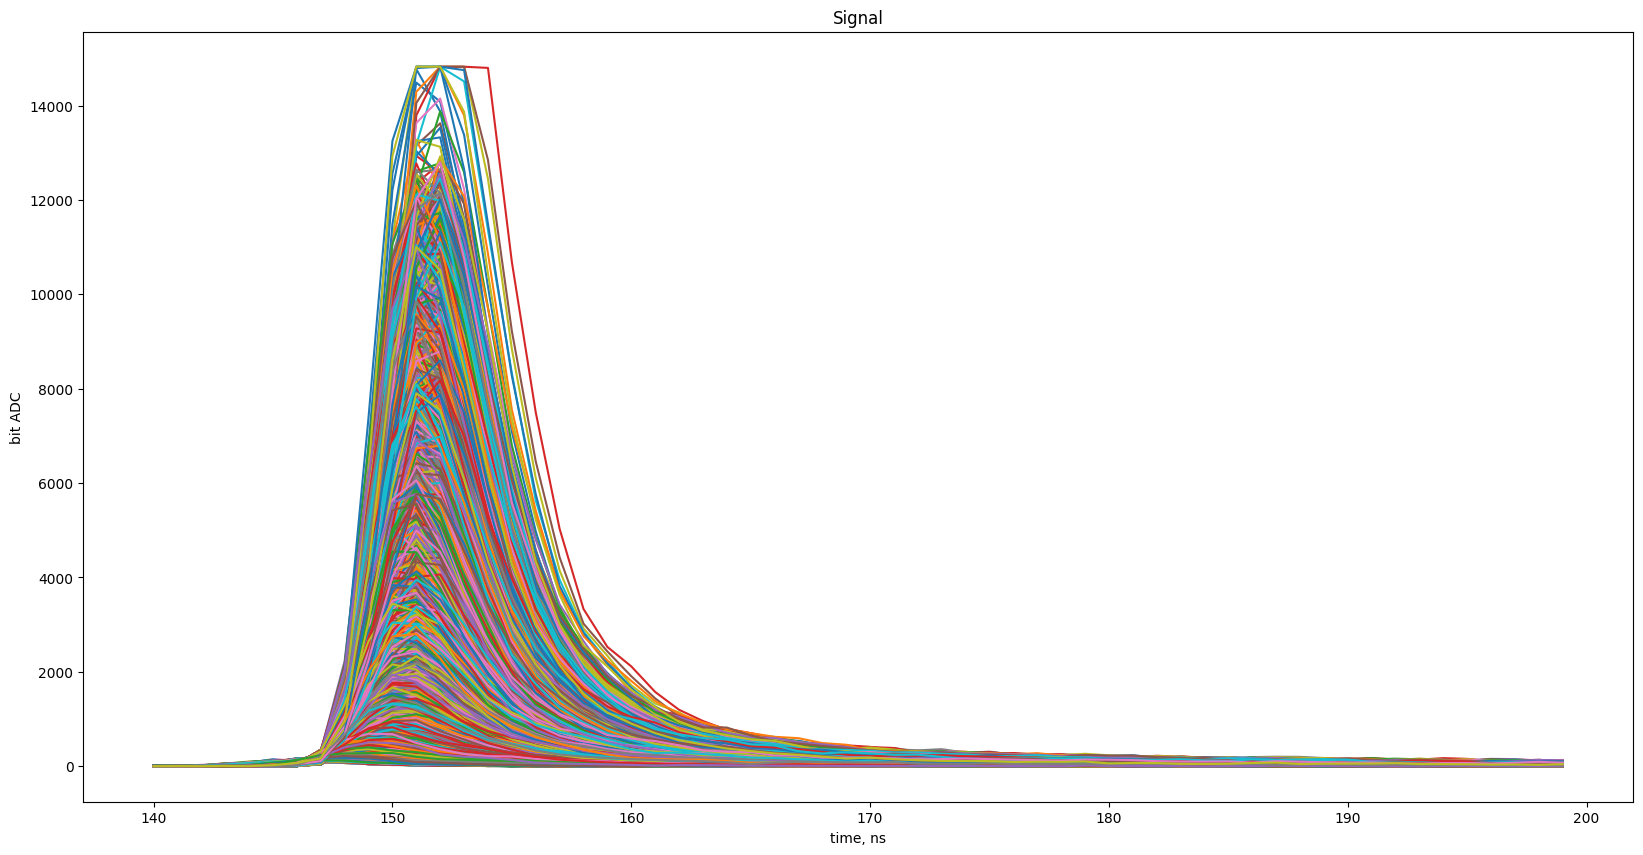

In [5]:
# Визуализация амплитуды сигналов
ax = (2**14-df_raw.T-1560)[140:200].plot(title='Signal' ,legend=None,figsize=(20,10))
ax.set_xlabel("time, ns")
ax.set_ylabel("bit ADC")


Выводы:
1. Исходный массив имеет размер 23 479 строк и 505 столбца. Пропусков, дубликатов не обнаружено.
2. Столбцы `0`, `1`, `2`, `3`, `504` являются служебной информацией (ID события, номер канала, длина записи).
3. Датасет представляет собой записи значений амплитуды сигнала в момент времени. Для каждого сигнала, после удаления служебной информации, остается 500 временных меток.
4. Визуально наблюдаются "обрезанные" пики сигналов. Судя по всему пиковые значения данных сигналов выходят за рамки диапазона измерения детектора.

### Предобработка данных и Feature Engineering

Согласно методическим указаниям подготовка данных сцинтилляционных детекторов для задачи кластеризации состоит из двух ключевых этапов: выделения (изоляции) полезного сигнала и его последующей параметризации (извлечения признаков).

1. Выделение полезного сигнала. Исходная кривая содержит шумы и избыточные данные в «хвостах», которые ухудшают качество кластеризации. Процесс изоляции сигнала включает следующие шаги:

    - Определение нулевой линии шума: рассчитывается как среднее арифметическое значение амплитуды по первым 50 отсчетам в левом хвосте кривой.
    
    - Поиск максимума: фиксируется индекс максимального значения амплитуды, который служит отправной точкой.
    
    - Определение окончания сигнала: точкой завершения сигнала считается момент, когда кривая приближается к нулевой линии и начинает отличаться от неё менее чем на три стандартных отклонения шума. На этом этапе полезный сигнал затухает, и начинает доминировать шум.
    
    - Введение отступа (оптимизация): полезно начинать отсчет не от самого максимума, а с отступом. В работе экспериментально доказано, что наилучшее разделение достигается при отступе от максимума на 40% от пиковой амплитуды.
    
2. Параметризация сигналов. Чтобы алгоритмы машинного обучения могли эффективно разделить сигналы, их представляют в виде векторов признаков, имеющих физический или статистический смысл. Из выделенного сигнала извлекаются следующие параметры:
  
    - Время высвечивания (tau): кривая аппроксимируется экспоненциальной зависимостью (или суммой быстрой и медленной компонент), откуда в явном виде извлекается характерное время затухания.
    
    - Параметр формы импульса (PSD — Pulse Shape Discrimination): рассчитывается отношение площадей под разными участками сигнала. Этот нормированный параметр позволяет разделять частицы разной природы независимо от их энергии.
    
    - Амплитуда и общая площадь: фиксируется максимальная высота пика и полный интеграл под кривой полезного сигнала.

In [6]:
# Вычисление теоретического значение амплитуды сигнала.
def exp_decay(t, A, tau):
    tau = max(tau, 1e-3)
    return A * np.exp(-t / tau)

def process_single_signal(raw_data, short_gate_len=5):
    # Расчет базовой линии
    baseline_zone = raw_data[:50]
    v_zero = np.mean(baseline_zone)
    sigma = np.std(baseline_zone)

    # Инверсия и центрирование
    centered_data = v_zero - raw_data
    centered_data = np.clip(centered_data, a_min=0, a_max=None)

    # Поиск максимума
    idx_max = np.argmax(centered_data)
    amplitude = centered_data[idx_max]

    # Если сигнал пустой, возвращаем нули и NaN для tau
    if amplitude <= 0:
        return {'amplitude': 0.0, 'volume': 0.0, 'psd': 0.0, 'tau': np.nan}

    # Поиск окончания сигнала
    tail_data = centered_data[idx_max:]
    noise_limit = 3 * sigma

    below_noise_indices = np.where(tail_data <= noise_limit)[0]
    if len(below_noise_indices) > 0:
        idx_end = idx_max + below_noise_indices[0]
    else:
        idx_end = len(centered_data) - 1

    useful_signal = centered_data[idx_max:idx_end+1]

    # Извлечение признаков
    volume = np.sum(useful_signal)

    long_gate = volume
    short_gate = np.sum(useful_signal[:short_gate_len])
    psd = (long_gate - short_gate) / (long_gate + 1e-9)

    tau = np.nan
    try:
        decay_level = amplitude * 0.60
        fit_start_relative = np.where(useful_signal <= decay_level)[0]

        if len(fit_start_relative) > 0:
            start_fit_idx = fit_start_relative[0]

            y_fit = useful_signal[start_fit_idx:]
            x_fit = np.arange(len(y_fit))

            if len(y_fit) > 2 and np.max(y_fit) > 1:
                popt, _ = curve_fit(exp_decay, x_fit, y_fit, p0=[y_fit[0], 10.0], maxfev=1000)
                if 0.1 < popt[1] < 500:
                    tau = popt[1]
    except Exception:
        pass

    return {
        'amplitude': amplitude,
        'volume': volume,
        'psd': psd,
        'tau': tau
    }

def prepare_dataset_for_clustering(df):
    signals_matrix = df.values
    features_list = []

    print("\nЗапуск обработки сигналов и извлечения признаков...")
    for i, row in enumerate(signals_matrix):
        features = process_single_signal(row)
        features_list.append(features)

    df_features = pd.DataFrame(features_list)

    # Считаем количество пропусков в tau перед заполнением
    nan_count = df_features['tau'].isna().sum()

    # Заполнение пропусков медианой
    if nan_count > 0:
        tau_median = df_features['tau'].median()
        df_features['tau'] = df_features['tau'].fillna(tau_median)

    return df_features

df_clustering_ready = prepare_dataset_for_clustering(df_raw)

print(f"\nИтоговый размер признаков: {df_clustering_ready.shape}")
print(f"Пропусков после обработки: {df_clustering_ready.isna().sum().sum()}")



Запуск обработки сигналов и извлечения признаков...


/tmp/ipykernel_8278/3233620783.py:55: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, _ = curve_fit(exp_decay, x_fit, y_fit, p0=[y_fit[0], 10.0], maxfev=1000)



Итоговый размер признаков: (23479, 4)
Пропусков после обработки: 0


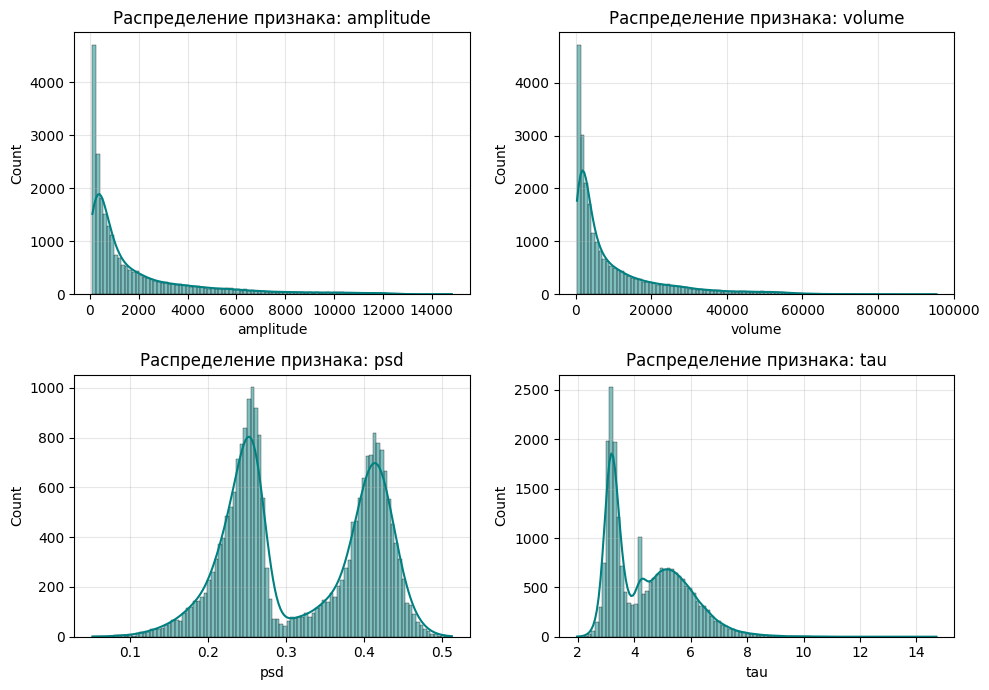

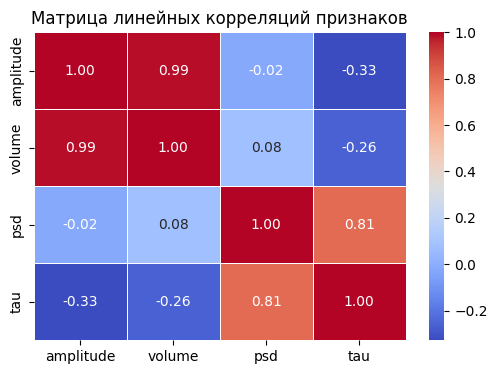

In [9]:
# 1. Визуализация распределений признаков
plt.figure(figsize=(10, 7))
for i, col in enumerate(df_clustering_ready.columns):
    plt.subplot(2, 2, i + 1)
    sns.histplot(df_clustering_ready[col], bins=100, kde=True, color='teal')
    plt.title(f'Распределение признака: {col}')
    plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 2. Матрица корреляций
plt.figure(figsize=(6, 4))
sns.heatmap(df_clustering_ready.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Матрица линейных корреляций признаков')
plt.show()


Выводы:
1. Распределения амплитуды (amplitude) и площади (volume). Оба графика имеют классическое экспоненциально затухающее распределение. Подавляющее большинство сигналов — это фоновые события низкой энергии (низкие амплитуды до 2000 и площади до 20000). Однако присутствуют редкие высокоэнергетические события, простирающиеся вплоть до амплитуды 14000+.
   
2. Распределение параметра формы (psd). График имеет четко выраженную бимодальную структуру (два независимых купола-пика):

    Первый пик (около 0.25): Самый массовый. Это «быстрые» сигналы, у которых вся энергия сосредоточена в начале импульса (гамма-кванты).
    
    Второй пик (около 0.41): Это «медленные» сигналы с затянутым, пологим хвостом (нейтроны).
    
    Вывод: Параметр PSD — идеальный разделитель для двух основных классов. Область между пиками (0.30–0.35) — это зона неопределенности или граница разделения, где алгоритмы кластеризации будут проводить барьер.
    
3. Распределение времени высвечивания (tau). Здесь тоже видна сложная многомодальная структура. Основной пик сосредоточен в районе 3.0–3.5 тактов (быстрая компонента высвечивания). Второй, более размытый купол находится в районе 5.0 тактов (медленная компонента).

    Вывод: Признак tau содержит чистую информацию о кинетике сцинтиллятора независимо от амплитуды. Он служит отличным независимым подтверждением для параметра PSD.
    
4. Матрица линейных корреляций

    Пара amplitude и volume (Корреляция 0.99): Почти абсолютная линейная зависимость, чем выше импульс, тем больше площадь под ним.
    
    Пара psd и tau (Корреляция 0.81): Высокая положительная корреляция.
    
    Корреляция энергии (amplitude/volume) с формой (psd/tau) близка к нулю (от -0.02 до -0.33):


Признаки (amplitude/volume) будут подвергнуты снижению размерности.


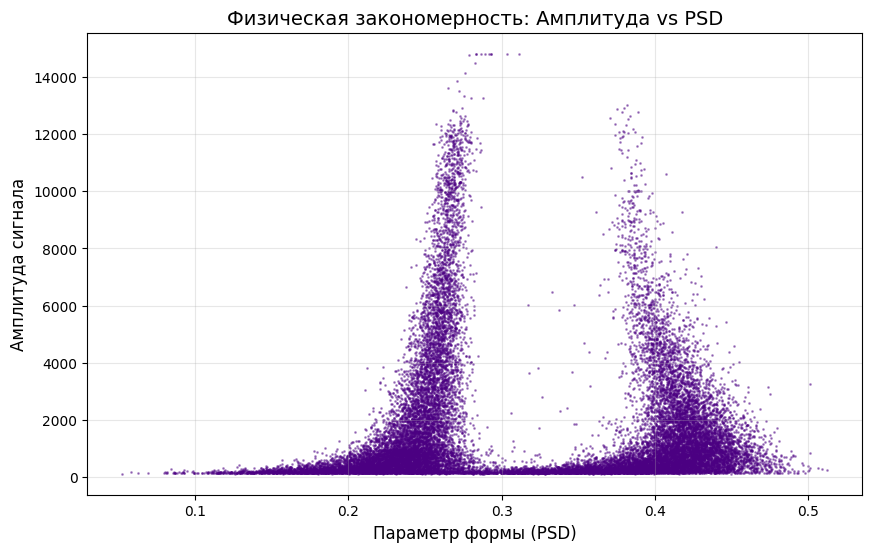

In [10]:
plt.figure(figsize=(10, 6))
# Строим плоскость PSD vs Amplitude
plt.scatter(df_clustering_ready['psd'], df_clustering_ready['amplitude'], s=1, alpha=0.4, c='indigo')
plt.title('Физическая закономерность: Амплитуда vs PSD', fontsize=14)
plt.xlabel('Параметр формы (PSD)', fontsize=12)
plt.ylabel('Амплитуда сигнала', fontsize=12)
plt.grid(True, alpha=0.3)
plt.show()


На графике отчетливо видны два обособленных вертикальных хвоста и прижатая к нижней оси область фона:

  - Левый хвост: Это гамма-кванты. У них быстрое время высвечивания, поэтому энергия быстро затухает, а значение PSD остается стабильно низким вне зависимости от роста амплитуды.

  - Правый хвост: Это нейтроны. У них присутствует медленная компонента высвечивания (пологий хвост), из-за чего доля площади в хвосте сигнала значительно выше.

  - Нижняя горизонтальная область (Амплитуда < 1000): Это зона низкоэнергетических фоновых шумов и шумов детектора. Здесь треки гамма и нейтронов сливаются, так как при малых амплитудах форме сигнала не хватает дискретизации для четкого разделения.

Исходная матрица (23479, 4) сжата попарно в (23479, 3)
Дисперсия, сохраненная в паре Энергии: 0.9928

Запуск подбора гиперпараметров...
Лучшая конфигурация для K-Means: K-Means (k-means++) (Silhouette: 0.5772)
Лучшая конфигурация для GMM: GMM (tied) (Silhouette: 0.5673)
Лучшая конфигурация для Agglomerative: Agglomerative (ward) (Silhouette: 0.5602)


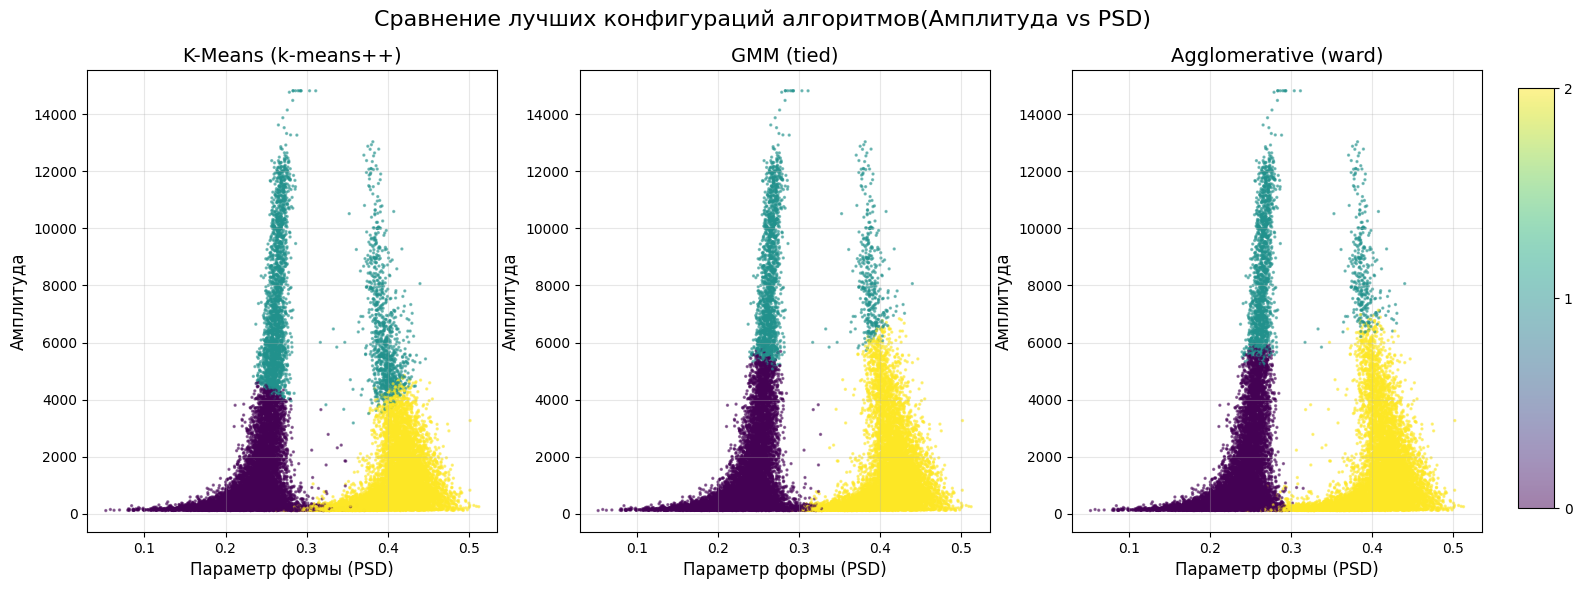

In [11]:
# Снижение размерности
# Стандартизируем исходные признаки
scaler_init = StandardScaler()
df_scaled_init = pd.DataFrame(scaler_init.fit_transform(df_clustering_ready), columns=df_clustering_ready.columns)

# 1. Сжимаем пару Энергии: amplitude и volume -> в 1 компоненту
pca_energy = PCA(n_components=1)
pc_energy = pca_energy.fit_transform(df_scaled_init[['amplitude', 'volume']])

# Объединяем полученные компоненты в новое пространство признаков
X_pca = np.hstack((pc_energy, df_scaled_init[['psd', 'tau']]))

# Финальное масштабирование полученных компонент PCA перед передачей в модели
scaler_final = StandardScaler()
X_scaled = scaler_final.fit_transform(X_pca)

print(f"Исходная матрица {df_clustering_ready.shape} сжата попарно в {X_scaled.shape}")
print(f"Дисперсия, сохраненная в паре Энергии: {pca_energy.explained_variance_ratio_[0]:.4f}")



# Физически корректная синхронизация цветов (по среднему PSD)
def map_clusters_by_psd(labels, df_psd):
    unique_labels = np.unique(labels)
    if len(unique_labels) != 3: return labels
    mean_psd = {lbl: df_psd[labels == lbl].mean() for lbl in unique_labels}
    sorted_by_psd = sorted(mean_psd.items(), key=lambda x: x[1])
    mapping = {sorted_by_psd[0][0]: 0, sorted_by_psd[1][0]: 1, sorted_by_psd[2][0]: 2}
    return np.vectorize(mapping.get)(labels)


# Подбор гиперпараметров
print("\nЗапуск подбора гиперпараметров...")
tuning_results = []

# Сетка для K-Means
for init_method in ['k-means++', 'random']:
    km_test = KMeans(n_clusters=3, init=init_method, random_state=42, n_init=10)
    labels = km_test.fit_predict(X_scaled)
    ch = calinski_harabasz_score(X_scaled, labels)
    sil = silhouette_score(X_scaled, labels, sample_size=5000, random_state=42)
    tuning_results.append({
        'Model_Type': 'K-Means',
        'Model_Name': f'K-Means ({init_method})',
        'CH_Score': ch,
        'Silhouette': sil,
        'Raw_Labels': labels
    })

# Сетка для GMM
for cov_type in ['tied', 'full', 'spherical', 'diag']:
    gmm_test = GaussianMixture(n_components=3, covariance_type=cov_type, random_state=42, n_init=3)
    labels = gmm_test.fit_predict(X_scaled)
    ch = calinski_harabasz_score(X_scaled, labels)
    sil = silhouette_score(X_scaled, labels, sample_size=5000, random_state=42)
    tuning_results.append({
        'Model_Type': 'GMM',
        'Model_Name': f'GMM ({cov_type})',
        'CH_Score': ch,
        'Silhouette': sil,
        'Raw_Labels': labels
    })

# Сетка для Иерархической кластеризации
for linkage_method in ['ward', 'complete', 'average']:
    agg_test = AgglomerativeClustering(n_clusters=3, linkage=linkage_method)
    labels = agg_test.fit_predict(X_scaled)
    ch = calinski_harabasz_score(X_scaled, labels)
    sil = silhouette_score(X_scaled, labels, sample_size=5000, random_state=42)
    tuning_results.append({
        'Model_Type': 'Agglomerative',
        'Model_Name': f'Agglomerative ({linkage_method})',
        'CH_Score': ch,
        'Silhouette': sil,
        'Raw_Labels': labels
    })

# Превращаем результаты в DataFrame для удобного поиска
df_all_runs = pd.DataFrame(tuning_results)


# Выбор лучшей модели по Silhouette
models_results = {}

for m_type in ['K-Means', 'GMM', 'Agglomerative']:
    df_sub = df_all_runs[df_all_runs['Model_Type'] == m_type]
    best_run = df_sub.loc[df_sub['Silhouette'].idxmax()]
    best_config_name = best_run['Model_Name']
    best_labels = best_run['Raw_Labels']

    print(f"Лучшая конфигурация для {m_type}: {best_config_name} (Silhouette: {best_run['Silhouette']:.4f})")

    # Сохраняем результат
    models_results[best_config_name] = map_clusters_by_psd(best_labels, df_clustering_ready['psd'])


# Отрисовка
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('Сравнение лучших конфигураций алгоритмов(Амплитуда vs PSD)', fontsize=16)

for i, (full_name, labels) in enumerate(models_results.items()):
    scatter = axes[i].scatter(
        df_clustering_ready['psd'],
        df_clustering_ready['amplitude'],
        c=labels,
        cmap='viridis',
        s=2,
        alpha=0.5,
        vmin=0,
        vmax=2
    )
    axes[i].set_title(full_name, fontsize=14)
    axes[i].set_xlabel('Параметр формы (PSD)', fontsize=12)
    axes[i].set_ylabel('Амплитуда', fontsize=12)
    axes[i].grid(True, alpha=0.3)

# Добавляем общую легенду цветов для понимания классов
cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])
cbar = fig.colorbar(scatter, cax=cbar_ax, ticks=[0, 1, 2])
cbar.set_ticklabels(['0', '1', '2'])

plt.subplots_adjust(right=0.9)
plt.show()


Выводы:
1. Интерпретация результатов моделей

- Все три алгоритма (K-Means, GMM, Agglomerative) выделили три выраженные физические группы (кластеры) сигналов:

    - Кластер 0 (Фиолетовый): «Гамма-кванты». Характеризуется низким параметром формы PSD (ок. 0.1 - 0.28).

    - Кластер 1 (Бирюзовый): «Высокоамплитудные всплески нейтронов и гамма-квантов». Имеет исключительно высокие значения амплитуды (от 5000 до 14000). Обладает вертикальной вытянутой структурой. За счет этого выделился в отдельный кластер.

    - Кластер 2 (Желтый): «Нейтроны». Смещен в область высоких значений PSD (ок. 0.35 - 0.5).

    - Визуально заметно, что алгоритмы провели жесткую окологоризонтальную границу при отделения 1-го кластера. Из-за этого верхние половины обоих хвостов слились в единый бирюзовый класс. Фактически все алгоритмы воспринимают оба этих хвоста, как единый класс, хотя в реальности это разные сигналы.
    Таким образом относительно корректное разделение произошло только к низу от горизонтальной границы, проведенной алгоритмами.

2. Различия в геометрии разделения:

- K-Means (k-means++): алгоритм минимизирует внутрикластерное расстояние (критерий компактности). На исходных данных он продемонстрировал лидерство по метрике Silhouette = 0.5772, но грубо разрезал физические треки по горизонтали в угоду создания сферических кластеров.

- GMM (tied): Гауссова смесь с привязанной ковариацией (tied) строит кластеры эллиптической формы с одинаковой геометрией. Она дает более гладкую, вероятностную границу при отделении бирюзового кластера (Silhouette: 0.5673).

- Agglomerative (ward): Иерархический метод (инициализация ward стремится минимизировать дисперсию внутри кластеров) показал схожую с GMM геометрию, но с чуть худшей (Silhouette: 0.5602). Однако показал лучший скор на каггл.

3. Влияние признаков
- Параметр формы (PSD): Является ключевым разделителем фаз. Он четко делит сигналы на две фундаментальные зоны: базовые/всплески (PSD < 0.3) и высокочастотные (PSD > 0.35). Между ними наблюдается физический зазор (переходная зона).

- Энергия (amplitude + volume через PCA): Метод главных компонент сохранил 99.28% дисперсии этой пары признаков. Сжатие избавило модель от мультиколлинеарности без потери информации.

4. Предложенные улучшения модели

- Тестирование плотностных алгоритмов (HDBSCAN / DBSCAN): График показывает, что кластеры имеют разную плотность и вытянутую форму. Плотностные методы помогут лучше выделить кластер 1 (бирюзовый) без жесткого отсечения снизу.

- Нелинейное снижение размерности (UMAP / t-SNE): Вместо линейного PCA для пары признаков, можно применить UMAP ко всему пространству (amplitude, volume, psd, tau) для поиска скрытых нелинейных взаимосвязей.

- Использование дополнительных метрик: Включить в подбор гиперпараметров индекс Дэвиса-Болдина (davies_bouldin_score), чтобы оценить компактность кластеров и расстояние между ними с другой математической точки зрения.


In [12]:
# Выбираем метки лучшей модели (Agglomerative (ward) показал наилучшую разделимость по метрике на каггл)
final_labels = models_results['Agglomerative (ward)']

# Присваиваем меткам кластеров порядковые номера
cluster_kmeans = pd.factorize(final_labels)[0]

# Создаем DataFrame согласно требованиям Kaggle (колонки 'id' и 'class')
submission = pd.DataFrame({
    'index': range(0, len(cluster_kmeans)),
    'cluster': cluster_kmeans
})

# Указываем путь сохранения на Google Диске
# Файл будет доступен в корне вашего Диска
output_path = '/content/submission.csv'

# 4. Сохранение файла
submission.to_csv(output_path, index=False)
print(f"Файл успешно сформирован и сохранен: {output_path}")



Файл успешно сформирован и сохранен: /content/submission.csv


### Результат на Kaggle

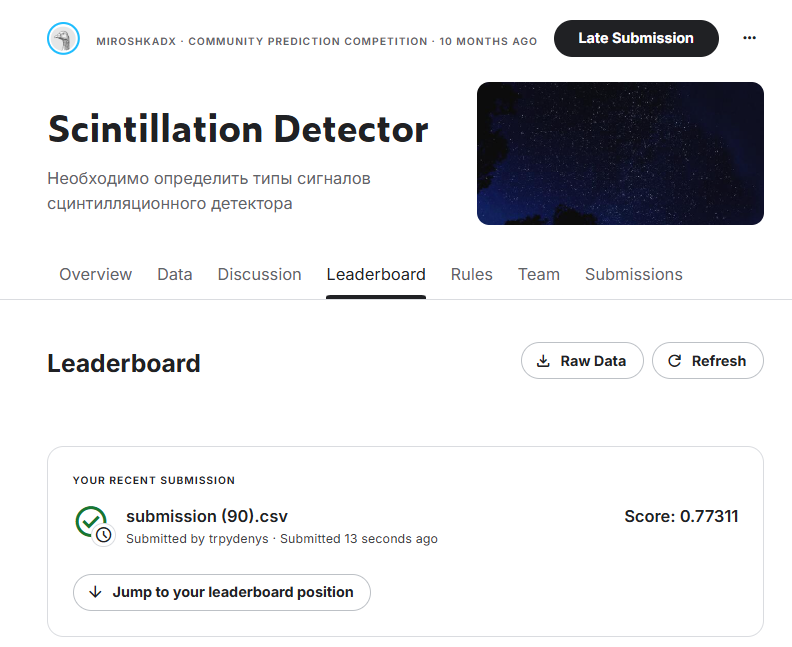